# Methanol Decomposition Reactor — Physics Digital Twin

**Physics model** with LHHW-type kinetics for methanol decomposition.

| Role | Variables |
|------|-----------|
| **Inputs (3)** | Inlet Temperature (°C), Inlet Pressure (bar_g), **Methanol** molar flow rate (kgmole/h) |
| **Outputs (8)** | Temp_0.2m … Temp_1m (°C), Outlet Pressure (bar_g), Total heat input (kW), Overall Conversion (%) |

**Reaction:** CH₃OH → CO + 2H₂

**Feed = methanol only** (no steam / water in this model).

## 1. Imports

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

DATA_FILE = Path("DATA.xlsx")
MEASUREMENT_POSITIONS_M = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
P_ATM_BAR = 1.01325

## 2. Load Excel — Data sheet only

Operating cases (3 inputs + 8 reference outputs) for validation. Reactor geometry is **fixed** (Section 3).

In [ ]:
def load_excel(path: Path):
    # Load and clean operating cases from Excel Data sheet
    raw = pd.read_excel(path, sheet_name="Data", header=[0, 1])
    # raw = dataframe with two-row header (column name + unit)

    raw.columns = [f"{name} ({unit})" if pd.notna(unit) and str(unit).strip() else str(name)
        for name, unit in raw.columns]
    # Flatten multi-level columns into strings like "Inlet Temperature (C)"

    # Rename columns for easier access: create a dataframe with short Pythonic column names for model inputs and outputs
    data = raw.rename(
        columns={
            "Inlet Temperature (C)": "T_in_C",
            "Inlet Pressure (bar_g)": "P_in_bar_g",
            "Inlet molar flow rate (kgmole/h)": "F_in_kgmole_h",
            "Temp_0.2m (C)": "T_0.2m_C",
            "Temp_0.4m (C)": "T_0.4m_C",
            "Temp_0.6m (C)": "T_0.6m_C",
            "Temp_0.8m (C)": "T_0.8m_C",
            "Temp_1m (C)": "T_1m_C",
            "Outlet Pressure (bar_g)": "P_out_bar_g",
            "Total heat input (KW)": "Q_total_kW",
            "Overall Conversion (%)": "X_overall_pct",
        }
    )
    # data = dataframe with short Python column names. The data variable makes a dataframe for all the varaibles needed to make
    # the model with short column name.

    ok = (
        data["X_overall_pct"].between(0,100)
        # Filter: conversion between 0% and 100% (remove failed runs)

        & data["Q_total_kW"].between(-132000, 0)
        # Filter: heat input between -132000 and 0 kW (sanity check)

        & data[["T_in_C", "P_in_bar_g", "F_in_kgmole_h"]].notna().all(axis=1)
        # Filter: all 3 inputs must be present (not missing)
    )
    # ok = boolean mask for valid simulation rows

    data = data.loc[ok].reset_index(drop=True)
    # Apply filter and reset row index to 0, 1, 2, ...

    return data
    # Return cleaned dataframe for validation


df = load_excel("DATA.xlsx")
# df = full cleaned dataset from DATA.xlsx

INPUT_COLS = ["T_in_C", "P_in_bar_g", "F_in_kgmole_h"]
# INPUT_COLS = list of 3 model input column names

OUTPUT_COLS = [
    "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C",
    "P_out_bar_g", "Q_total_kW", "X_overall_pct",
]
# OUTPUT_COLS = list of 8 model output column names

print(f"Valid rows: {len(df)}")
# Print count of rows after filtering bad simulations

display(df[INPUT_COLS].head())
# Show first 5 input rows for quick inspection

Valid rows: 1055


,T_in_C,P_in_bar_g,F_in_kgmole_h
0,200,0.4,0.10
1,200,0.4,0.35
2,200,0.4,0.60
3,200,0.4,0.85
4,200,0.4,1.10


## 3. Fixed reactor geometry & kinetic parameters

**Reaction:** CH₃OH → CO + 2H₂ | **ΔH = 2.2e4 kcal/kgmol**

**Fixed geometry (always these values):**

| Parameter | Value | Unit |
|-----------|-------|------|
| Reactor diameter | 0.1 | m |
| Reactor length | 1.0 | m |
| Heat medium side HTC | 115 | W/m²/°C |
| Heat medium side temperature | 275 | °C |
| Catalyst bed void fraction | 0.33 | — |

In [ ]:
# ============================================================
# 1. UNIVERSAL GAS CONSTANT
# ============================================================
R = 6036.8               # kcal/kgmole
# R = universal gas constant; used in ideal gas law and Arrhenius terms

# ============================================================
# 2. FIXED REACTOR PARAMETERS
# ============================================================
D = 0.1                  # Reactor diameter [m]
# D = inner tube diameter of the catalyst bed

L = 1.0                  # Reactor length [m]
# L = axial length of reactor (integration runs from 0 to L)

h_heat = 115.0           # Heating-side HTC [W/m2.C]
# h_heat = wall heat transfer coefficient from heating jacket to gas

T_heat_C = 275.0         # Heating medium temperature [°C]
# T_heat_C = temperature of external heating fluid (driving force for heat in)

epsilon = 0.33           # Catalyst bed void fraction [-]
# epsilon = fraction of bed volume that is gas (not solid catalyst)

dp = 1.000e-3            # Catalyst particle diameter [m]
# dp = catalyst pellet size; used in Ergun pressure-drop equation

Ac = np.pi * D**2 / 4    # Reactor cross-sectional area [m²]
# Ac = flow area inside the circular tube (π·D²/4)

perimeter = np.pi * D    # Heat-transfer perimeter [m]
# perimeter = wetted wall length per meter of bed for heat transfer

# ============================================================
# 3. MOLECULAR WEIGHTS
# ============================================================
MW_CH3OH = 32.04e-3      # kg/mol
# MW_CH3OH = methanol molecular weight for mass-flow calculations

MW_CO    = 28.01e-3      # kg/mol
# MW_CO = carbon monoxide molecular weight

MW_H2    = 2.016e-3      # kg/mol
# MW_H2 = hydrogen molecular weight

# ============================================================
# 4. HEAT CAPACITIES
# ============================================================
Cp_CH3OH = 43.0          # J/mol.K
# Cp_CH3OH = molar heat capacity of methanol (energy balance)

Cp_CO    = 29.0          # J/mol.K
# Cp_CO = molar heat capacity of CO

Cp_H2    = 29.0          # J/mol.K
# Cp_H2 = molar heat capacity of hydrogen

# ============================================================
# 5. REACTION KINETICS
# r = [7e10 exp(-19120/RT) C_CH3OH] / [1 + 1e7 exp(-6036.8/RT) C_CO]
# ============================================================
A_kinetic = 7.0000e10
# A_kinetic = pre-exponential factor for main decomposition rate

E_kinetic = 19120.0      # J/mol ? Units are not correct. As per "Physics parameters" tab, it should be kcal/kgmol
# E_kinetic = activation energy for methanol reaction [J/mol]

A_CO = 1.0000e7
# A_CO = pre-exponential factor for CO adsorption in LHHW denominator

E_CO = 6036.8            # J/mol
# E_CO = activation energy for CO adsorption term [J/mol]

# ============================================================
# 6. REACTION ENTHALPY  —  CH3OH -> CO + 2H2
# ============================================================
delta_H = 2.2e4          # kcal/kgmol
# delta_H = endothermic heat of reaction per kgmole CH3OH reacted [kcal/kgmol]

print("Fixed reactor parameters:")
# Print summary header

print(f"  D        = {D} m")
# Show reactor diameter

print(f"  L        = {L} m")
# Show reactor length

print(f"  HTC      = {h_heat} W/m²-K")
# Show heat transfer coefficient

print(f"  T_heat   = {T_heat_C} °C")
# Show heating medium temperature

print(f"  epsilon  = {epsilon}")
# Show bed void fraction

print(f"  R        = {R} kcal/kgmole")
# Show gas constant

print(f"  delta_H  = {delta_H:.1e} kcal/kgmol")
# Show reaction enthalpy in kcal/kgmol

Fixed reactor parameters:
  D        = 0.1 m
  L        = 1.0 m
  HTC      = 115.0 W/m²-K
  T_heat   = 275.0 °C
  epsilon  = 0.33
  delta_H  = 90.5 kJ/mol


## 4. Unit conversions (Excel inputs → model units)

In [8]:
def bar_g_to_Pa(P_bar_g):
    # P_bar_g = inlet/outlet gauge pressure from Excel [bar_g]
    """Convert gauge pressure (bar_g) to absolute pressure [Pa]."""
    return (P_bar_g + P_ATM_BAR) * 1.0e5
    # Absolute pressure [Pa] = (gauge + atmospheric) converted bar → Pa


def Pa_to_bar_g(P_Pa):
    # P_Pa = absolute pressure from ODE model [Pa]
    """Convert absolute pressure [Pa] to gauge pressure (bar_g)."""
    return P_Pa / 1.0e5 - P_ATM_BAR
    # bar_g = absolute Pa → bar, then subtract atmospheric bar


def kgmole_h_to_mol_s(F_kgmole_h):
    # F_kgmole_h = methanol molar flow from Excel [kgmole/h]
    """Convert methanol molar flow from kgmole/h (Excel) to mol/s (model)."""
    return F_kgmole_h * 1000.0 / 3600.0
    # mol/s = kgmole/h × 1000 mol/kgmole ÷ 3600 s/h

## 5. Physics model — reaction rate & reactor ODEs

**All temperatures in °C** (Kelvin used only inside Arrhenius / ideal-gas formulas).

State vector: `[F_CH3OH, F_CO, F_H2, T(°C), P(Pa), Q(W)]`

Reaction pathway: **CH₃OH → CO + 2H₂**

**Conversion:** calculated as decimal internally, reported as **percentage (%)** in all outputs.

In [10]:
# Returns the LHHW reaction rate [mol/(m³·s)] for given T, P, and species flows
def reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2):
    T_abs = T_C + 273.15

    F_total = F_CH3OH + F_CO + F_H2
    F_total = max(F_total, 1e-12)

    y_CH3OH = F_CH3OH / F_total
    y_CO = F_CO / F_total

    C_total = P / (R * T_abs)

    C_CH3OH = y_CH3OH * C_total
    C_CO = y_CO * C_total

    numerator = (
        A_kinetic
        * np.exp(-E_kinetic / (R * T_abs))
        * C_CH3OH
    )

    denominator = (
        1.0
        + A_CO * np.exp(-E_CO / (R * T_abs)) * C_CO
    )

    return numerator / denominator


def reactor_model(z, y):
    # ODE system: how state variables change along reactor length z [m]
    F_CH3OH = max(y[0], 1e-12)
    # F_CH3OH = methanol molar flow [mol/s]; state index 0

    F_CO = max(y[1], 0.0)
    # F_CO = CO molar flow [mol/s]; state index 1

    F_H2 = max(y[2], 0.0)
    # F_H2 = hydrogen molar flow [mol/s]; state index 2

    T_C = y[3]
    # T_C = gas temperature [°C]; state index 3

    P = max(y[4], 1.0e3)
    # P = absolute gas pressure [Pa]; state index 4; floor avoids zero pressure

    Q = y[5]
    # Q = cumulative heat transferred into bed [W]; state index 5

    F_total = F_CH3OH + F_CO + F_H2
    # F_total = sum of all species flows at this axial position

    r = reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2)
    # r = local volumetric reaction rate [mol/(m³·s)]

    reaction_per_length = r * Ac
    # reaction_per_length = molar reaction rate per meter of bed [mol/(s·m)]

    # CH3OH -> CO + 2H2 stoichiometry
    dF_CH3OH_dz = -reaction_per_length
    # Methanol is consumed along the bed

    dF_CO_dz = reaction_per_length
    # CO is produced 1 mol per mol CH3OH reacted

    dF_H2_dz = 2.0 * reaction_per_length
    # H2 is produced 2 mol per mol CH3OH reacted

    q_transfer = h_heat * perimeter * (T_heat_C - T_C)
    # q_transfer = wall heat flux into gas [W/m] (positive when T_C < T_heat_C)

    Cp_flow = (
        F_CH3OH * Cp_CH3OH
        + F_CO * Cp_CO
        + F_H2 * Cp_H2
    )
    # Cp_flow = total heat capacity flow of gas stream [J/(s·K)]

    Cp_flow = max(Cp_flow, 1e-9)
    # Avoid division by zero in temperature ODE

    q_reaction = delta_H * reaction_per_length
    # q_reaction = heat absorbed by endothermic reaction [W/m]

    dT_dz = (q_transfer - q_reaction) / Cp_flow
    # dT_dz = temperature gradient along bed [°C/m]

    mass_flow = (
        F_CH3OH * MW_CH3OH
        + F_CO * MW_CO
        + F_H2 * MW_H2
    )
    # mass_flow = total gas mass flow rate [kg/s]

    MW_mix = mass_flow / max(F_total, 1e-12)
    # MW_mix = average molecular weight of gas mixture [kg/mol]

    T_abs = T_C + 273.15
    # T_abs = Kelvin temperature for density calculation only

    rho = P * MW_mix / (R * T_abs)
    # rho = gas density from ideal gas law [kg/m³]

    velocity = mass_flow / max(rho * Ac, 1e-12)
    # velocity = superficial gas velocity through bed [m/s]

    mu = 2.0e-5  # Pa.s
    # mu = dynamic gas viscosity for Ergun equation [Pa·s]

    viscous_term = (
        150.0 * mu * (1.0 - epsilon) ** 2
        / (epsilon ** 3 * dp ** 2) * velocity
    )
    # viscous_term = viscous contribution to Ergun pressure gradient [Pa/m]

    inertial_term = (
        1.75 * rho * (1.0 - epsilon)
        / (epsilon ** 3 * dp) * velocity ** 2
    )
    # inertial_term = inertial contribution to Ergun pressure gradient [Pa/m]

    dP_dz = -(viscous_term + inertial_term)
    # dP_dz = pressure drop along bed [Pa/m] (negative = pressure decreases)

    dQ_dz = q_transfer
    # dQ_dz = rate of heat accumulation along bed [W/m]

    return [
        dF_CH3OH_dz,
        dF_CO_dz,
        dF_H2_dz,
        dT_dz,
        dP_dz,
        dQ_dz,
    ]
    # Return all 6 ODE derivatives for the solver

## 6. Digital twin — 3 inputs → 8 outputs

In [11]:
def predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h, n_points=300):
    # Digital twin: 3 plant inputs → 8 outputs (+ profiles and outlet flows)
    """
    INPUTS (plant / Excel units):
        T_in_C           — Inlet Temperature [°C]
        P_in_bar_g       — Inlet Pressure [bar_g]
        F_in_kgmole_h    — Inlet methanol molar flow rate [kgmole/h]

    OUTPUTS:
        T_0.2m_C … T_1m_C  — axial temperatures [°C]
        P_out_bar_g        — outlet pressure [bar_g]
        Q_total_kW         — total heat input [kW]
        X_overall_pct      — overall methanol conversion [%]
    """
    F_CH3OH_in = kgmole_h_to_mol_s(F_in_kgmole_h)
    # F_CH3OH_in = inlet methanol flow converted to [mol/s]

    P_in_Pa = bar_g_to_Pa(P_in_bar_g)
    # P_in_Pa = inlet absolute pressure [Pa] for the ODE model

    y0 = [
        F_CH3OH_in,
        0.0,       # F_CO_in
        0.0,       # F_H2_in
        T_in_C,
        P_in_Pa,
        0.0,       # Q
    ]
    # y0 = initial state at z=0: [F_CH3OH, F_CO, F_H2, T_C, P, Q]

    z_eval = np.linspace(0.0, L, n_points)
    # z_eval = axial grid points from inlet (0) to outlet (L) [m]

    sol = solve_ivp(
        reactor_model,
        (0.0, L),
        y0,
        t_eval=z_eval,
        method="BDF",
        rtol=1e-6,
        atol=1e-9,
    )
    # Integrate ODEs along bed; BDF handles stiff kinetics

    if not sol.success:
        raise RuntimeError(sol.message)
    # Raise error if ODE solver failed

    F_CH3OH_out = sol.y[0, -1]
    # F_CH3OH_out = methanol flow at reactor outlet [mol/s]

    T_profile_C = sol.y[3]
    # T_profile_C = full axial temperature profile [°C] along z

    P_out_Pa = sol.y[4, -1]
    # P_out_Pa = outlet absolute pressure [Pa]

    Q_total_W = sol.y[5, -1]
    # Q_total_W = total heat transferred into bed at outlet [W]

    T_axial_C = np.interp(MEASUREMENT_POSITIONS_M, sol.t, T_profile_C)
    # T_axial_C = temperatures at Excel positions (0.2, 0.4, …, 1.0 m)

    X_overall_pct = (F_CH3OH_in - F_CH3OH_out) / F_CH3OH_in * 100.0
    # X_overall_pct = methanol conversion as percentage [%]

    Q_kW = Q_total_W / 1000.0
    # Q_kW = total heat input reported in kilowatts [kW]

    return {
        "T_0.2m_C": float(T_axial_C[0]),
        # T at z = 0.2 m [°C] ?? how does program know that this T_axial_C[0] is at 0.2m. Same with other locations.
        #at the start of the program we have made a numpy array "Measurement_Positions_M" in that array i ahve defined 
        #the positions above you can see it is defined.
        "T_0.4m_C": float(T_axial_C[1]),
        # T at z = 0.4 m [°C]

        "T_0.6m_C": float(T_axial_C[2]),
        # T at z = 0.6 m [°C]

        "T_0.8m_C": float(T_axial_C[3]),
        # T at z = 0.8 m [°C]

        "T_1m_C": float(T_axial_C[4]),
        # Outlet temperature at z = 1.0 m [°C]

        "P_out_bar_g": float(Pa_to_bar_g(P_out_Pa)),
        # Outlet gauge pressure converted from Pa to bar_g

        "Q_total_kW": float(Q_kW),
        # Total heat transferred into bed [kW]

        "X_overall_pct": float(X_overall_pct),
        # Methanol conversion [%]

        "z_m": sol.t,
        # Axial positions along full integration grid [m]

        "T_profile_C": T_profile_C,
        # Full axial temperature profile [°C] at each z_m point

        "F_CH3OH_out": float(F_CH3OH_out),
        # Methanol molar flow at outlet [mol/s]

        "F_CO_out": float(sol.y[1, -1]),
        # CO molar flow at outlet [mol/s]

        "F_H2_out": float(sol.y[2, -1]),
        # H2 molar flow at outlet [mol/s]
    }

## 7. Example run — single operating point


      METHANOL DECOMPOSITION PHYSICS MODEL

REACTION:
CH3OH -> CO + 2H2

INPUTS:
  Inlet Temperature     : 200.00 °C
  Inlet Pressure        : 0.400 bar_g
  Inlet methanol flow   : 0.100 kgmole/h

AXIAL TEMPERATURE PROFILE:
  Temp_0.2m = 53.02 °C
  Temp_0.4m = 250.74 °C
  Temp_0.6m = 273.78 °C
  Temp_0.8m = 274.94 °C
  Temp_1m = 275.00 °C

OUTLET RESULTS:
  Outlet temperature    : 275.00 °C
  Outlet pressure       : 0.2790 bar_g
  Total heat input      : 2.9292 kW
  Overall conversion    : 100.00 %

OUTLET MOLAR FLOWS:
  CH3OH = -3.234928e-11 mol/s
  CO    = 2.777778e-02 mol/s
  H2    = 5.555556e-02 mol/s


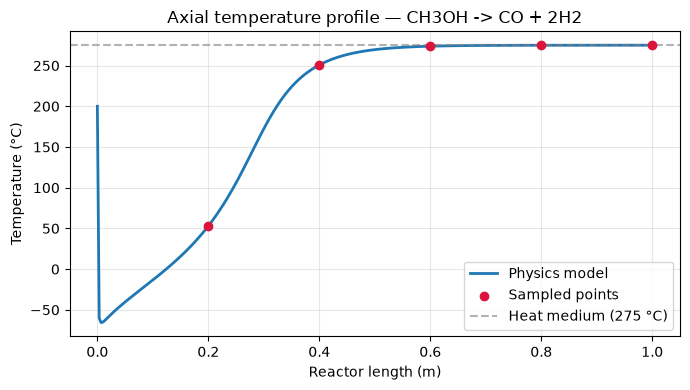

In [11]:
T_in_C = 200.0
# T_in_C = example inlet temperature [°C]

P_in_bar_g = 0.4
# P_in_bar_g = example inlet gauge pressure [bar_g]

F_in_kgmole_h = 0.1
# F_in_kgmole_h = example methanol-only inlet flow [kgmole/h]

pred = predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h)
# pred = dict of all model outputs for this operating point

print("\n" + "=" * 55)
# Print section divider

print("      METHANOL DECOMPOSITION PHYSICS MODEL")
# Print model title

print("=" * 55)
# Print closing divider

print("\nREACTION:")
# Print reaction section header

print("CH3OH -> CO + 2H2")
# Show stoichiometry being modeled

print("\nINPUTS:")
# Print inputs section header

print(f"  Inlet Temperature     : {T_in_C:.2f} °C")
# Display inlet temperature

print(f"  Inlet Pressure        : {P_in_bar_g:.3f} bar_g")
# Display inlet gauge pressure

print(f"  Inlet methanol flow   : {F_in_kgmole_h:.3f} kgmole/h")
# Display methanol feed flow (only species in feed)

print("\nAXIAL TEMPERATURE PROFILE:")
# Print axial temperature section header

for z, key in zip(MEASUREMENT_POSITIONS_M, [
    "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C"
]):
    # Loop over measurement positions and matching output keys
    print(f"  Temp_{z:g}m = {pred[key]:.2f} °C")
    # Print temperature at each axial location [°C]

print("\nOUTLET RESULTS:")
# Print outlet results section header

print(f"  Outlet temperature    : {pred['T_1m_C']:.2f} °C")
# Outlet gas temperature at z = 1.0 m

print(f"  Outlet pressure       : {pred['P_out_bar_g']:.4f} bar_g")
# Outlet gauge pressure

print(f"  Total heat input      : {pred['Q_total_kW']:.4f} kW")
# Total heat transferred into the bed [kW]

print(f"  Overall conversion    : {pred['X_overall_pct']:.2f} %")
# Methanol conversion as percentage [%]

print("\nOUTLET MOLAR FLOWS:")
# Print outlet species flows section

print(f"  CH3OH = {pred['F_CH3OH_out']:.6e} mol/s")
# Remaining methanol flow at outlet [mol/s]

print(f"  CO    = {pred['F_CO_out']:.6e} mol/s")
# CO produced at outlet [mol/s]

print(f"  H2    = {pred['F_H2_out']:.6e} mol/s")
# H2 produced at outlet [mol/s]

print("=" * 55)
# Print final divider

fig, ax = plt.subplots(figsize=(7, 4))
# Create figure and axes for temperature profile plot

ax.plot(pred["z_m"], pred["T_profile_C"], lw=2, label="Physics model")
# Plot full axial temperature profile; z_m = position [m], T_profile_C = T [°C]

ax.scatter(
    MEASUREMENT_POSITIONS_M,
    [pred["T_0.2m_C"], pred["T_0.4m_C"], pred["T_0.6m_C"], pred["T_0.8m_C"], pred["T_1m_C"]],
    color="crimson", zorder=5, label="Sampled points",
)
# Mark the 5 Excel measurement temperatures on the profile

ax.axhline(T_heat_C, color="gray", ls="--", alpha=0.6, label=f"Heat medium ({T_heat_C:.0f} °C)")
# Horizontal reference line at heating medium temperature

ax.set_xlabel("Reactor length (m)")
# X-axis label: axial position along bed

ax.set_ylabel("Temperature (°C)")
# Y-axis label: gas temperature

ax.set_title("Axial temperature profile — CH3OH -> CO + 2H2")
# Plot title showing reaction pathway

ax.legend()
# Show legend for model curve, points, and reference line

ax.grid(True, alpha=0.3)
# Add light grid for readability

plt.tight_layout()
# Adjust layout to prevent label clipping

plt.show()
# Display the temperature profile figure

## 8. Compare with Excel Data sheet (inputs only)

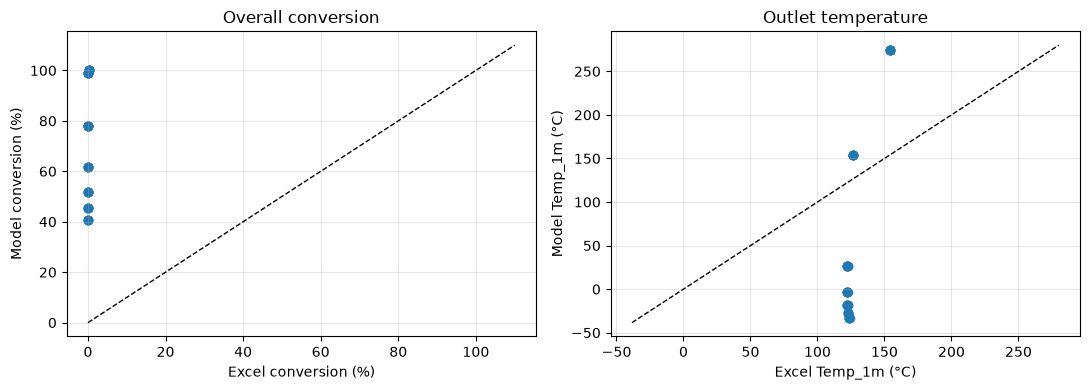

,Output,Excel,Physics model,Abs error
0,T_0.2m_C,113.6000,53.0226,60.5774
1,T_0.4m_C,125.2000,250.7440,125.5440
2,T_0.6m_C,135.9000,273.7801,137.8801
3,T_0.8m_C,145.5000,274.9390,129.4390
4,T_1m_C,154.1000,274.9970,120.8970
5,P_out_bar_g,0.3691,0.2790,0.0901
6,Q_total_kW,-0.7511,2.9292,3.6803
7,X_overall_pct,0.3086,100.0000,99.6914


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Create figure with 2 side-by-side subplots for validation charts

axes[0].scatter(results_ok["X_overall_pct_excel"], results_ok["X_overall_pct_pred"], alpha=0.7)
# Plot Excel vs model conversion for all successful cases

lim = max(results_ok["X_overall_pct_excel"].max(), results_ok["X_overall_pct_pred"].max()) * 1.1
# Set axis limit slightly above max value for padding

axes[0].plot([0, lim], [0, lim], "k--", lw=1)
# Draw perfect-match diagonal line (y = x)

axes[0].set_xlabel("Excel conversion (%)")
# Label x-axis for conversion plot

axes[0].set_ylabel("Model conversion (%)")
# Label y-axis for conversion plot

axes[0].set_title("Overall conversion")
# Title for conversion comparison plot

axes[0].grid(True, alpha=0.3)
# Add grid to conversion plot

axes[1].scatter(results_ok["T_1m_C_excel"], results_ok["T_1m_C_pred"], alpha=0.7)
# Plot Excel vs model outlet temperature

t0 = min(results_ok["T_1m_C_excel"].min(), results_ok["T_1m_C_pred"].min()) - 5
# Lower bound for temperature axis with margin

t1 = max(results_ok["T_1m_C_excel"].max(), results_ok["T_1m_C_pred"].max()) + 5
# Upper bound for temperature axis with margin

axes[1].plot([t0, t1], [t0, t1], "k--", lw=1)
# Draw perfect-match diagonal for temperature

axes[1].set_xlabel("Excel Temp_1m (°C)")
# Label x-axis for temperature plot

axes[1].set_ylabel("Model Temp_1m (°C)")
# Label y-axis for temperature plot

axes[1].set_title("Outlet temperature")
# Title for outlet temperature comparison

axes[1].grid(True, alpha=0.3)
# Add grid to temperature plot

plt.tight_layout()
# Adjust subplot spacing

plt.show()
# Display both validation plots

r0 = results_ok.iloc[0]
# Pick first successful row for detailed error table

compare = pd.DataFrame({
    "Output": OUTPUT_COLS,
    "Excel": [r0[f"{c}_excel"] for c in OUTPUT_COLS],
    "Physics model": [r0[f"{c}_pred"] for c in OUTPUT_COLS],
})
# Build table comparing all 8 outputs for one case

compare["Abs error"] = (compare["Physics model"] - compare["Excel"]).abs()
# Compute absolute difference between model and Excel for each output

display(compare.round(4))
# Show comparison table rounded to 4 decimals